### Notebook 03 — Regional Fishing-Effort Trend Analysis

**Research question**

> Which regions are increasing, decreasing, or remaining stable in fishing effort over time?

This notebook is the next step after cleaning and spatiotemporal aggregation. It tests whether fishing effort has declined in particular GFW spatial cells before we move to clustering or investigate possible causes.

**Important interpretation**

The current AIS dataset contains fishing-active observations. Therefore, `fishing_hours` is the primary measure of fishing effort. This notebook does **not** claim to measure biological fish productivity.

`Cleaned AIS → Monthly cell effort → Annual cell effort → Temporal trends → Regional trend classification → Spatial identification of declining regions`

Missing months are **not** filled with zero.


### 1. Setup

The notebook uses the monthly cell-level dataset produced in Notebook 02.

Expected columns include `year`, `month`, `cell_ll_lat`, `cell_ll_lon`, `fishing_hours`, `total_hours`, `active_vessels`, and `active_days`.


In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, spearmanr

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

BASE_DIR = Path("..")
PROCESSED_DIR = BASE_DIR / "outputs" / "processed"
ANALYSIS_DIR = BASE_DIR / "outputs" / "analysis"

# Notebook 02 writes monthly_cell.parquet to outputs/analysis, not outputs/processed.
MONTHLY_CELL_PATH = ANALYSIS_DIR / "monthly_cell.parquet"
MONTHLY_CELL_FALLBACK = PROCESSED_DIR / "monthly_cell.parquet"
TREND_PATH = ANALYSIS_DIR / "cell_effort_trends.parquet"

print("Monthly cell path (primary):", MONTHLY_CELL_PATH)
print("Exists:", MONTHLY_CELL_PATH.exists())
print("Monthly cell path (fallback):", MONTHLY_CELL_FALLBACK)
print("Exists:", MONTHLY_CELL_FALLBACK.exists())


Monthly cell path (primary): ..\outputs\analysis\monthly_cell.parquet
Exists: True
Monthly cell path (fallback): ..\outputs\processed\monthly_cell.parquet
Exists: False


### 2. Load monthly cell-level data

If `monthly_cell.parquet` is not present, the fallback reconstructs the monthly aggregation from `ais_cleaned.parquet`.


In [18]:
ais_path = PROCESSED_DIR / "ais_cleaned.parquet"

if MONTHLY_CELL_PATH.exists():
    monthly_cell = pd.read_parquet(MONTHLY_CELL_PATH)
elif MONTHLY_CELL_FALLBACK.exists():
    monthly_cell = pd.read_parquet(MONTHLY_CELL_FALLBACK)
else:
    ais = pd.read_parquet(ais_path)
    monthly_cell = (
        ais.groupby(
            ["year", "month", "cell_ll_lat", "cell_ll_lon"],
            as_index=False
        )
        .agg(
            total_hours=("hours", "sum"),
            fishing_hours=("fishing_hours", "sum"),
            active_vessels=("mmsi", "nunique"),
            active_days=("date", "nunique"),
        )
    )
    monthly_cell["fishing_ratio"] = np.where(
        monthly_cell["total_hours"] > 0,
        monthly_cell["fishing_hours"] / monthly_cell["total_hours"],
        np.nan,
    )

expected_monthly = {"year", "month", "cell_ll_lat", "cell_ll_lon",
                    "fishing_hours", "total_hours", "active_vessels", "active_days"}
missing = expected_monthly - set(monthly_cell.columns)
if missing:
    raise KeyError(f"monthly_cell is missing expected columns: {sorted(missing)}")

print("Shape:", monthly_cell.shape)
print(monthly_cell.head())


Shape: (149693, 9)
   year  month  cell_ll_lat  cell_ll_lon  total_hours  fishing_hours  \
0  2012      2      11.7000      74.9000       7.6377         3.1729   
1  2012      2      12.5000      74.6000       3.7586         3.7586   
2  2012      2      12.5000      74.7000       6.0836         6.0836   
3  2012      2      12.6000      74.6000       2.9963         2.9963   
4  2012      2      12.7000      74.6000       1.7338         1.7338   

   active_vessels  active_days  fishing_ratio  
0               1            2         0.4154  
1               1            1         1.0000  
2               1            1         1.0000  
3               1            1         1.0000  
4               1            1         1.0000  


### 3. Verify temporal coverage

The source data do not contain every month in every year. Missing months represent unavailable data, not zero fishing effort.

The main trend period is **2015–2024**, which has substantially better monthly coverage than the early years. The 2017 missing month remains missing rather than being converted to zero.


In [19]:
coverage = (
    monthly_cell.groupby("year")["month"]
    .nunique()
    .rename("months_available")
    .reset_index()
)
coverage["coverage_pct"] = coverage["months_available"] / 12 * 100
display(coverage)

TREND_START_YEAR = 2015
TREND_END_YEAR = 2024

trend_monthly = monthly_cell[
    monthly_cell["year"].between(TREND_START_YEAR, TREND_END_YEAR)
].copy()

print(f"Trend period: {TREND_START_YEAR}-{TREND_END_YEAR}")
print("Rows:", len(trend_monthly))


,year,months_available,coverage_pct
0,2012,11,91.6667
1,2013,6,50.0000
2,2014,9,75.0000
3,2015,12,100.0000
4,2016,12,100.0000
5,2017,11,91.6667
6,2018,12,100.0000
7,2019,12,100.0000
8,2020,11,91.6667
9,2021,12,100.0000


Trend period: 2015-2024
Rows: 148591


### 4. Build annual regional effort measures

For each spatial cell and year we calculate:

- `fishing_hours` — total observed fishing effort
- `vessel_months` — number of active vessels summed across months (a vessel present in several months is counted several times)
- `active_vessels_unique` — true number of unique vessels in that cell-year (recomputed from `ais_cleaned.parquet` when available; otherwise NaN)
- `active_days` — observed dates, summed across months (dates do not repeat across months, so the sum equals the annual total)
- `months_available` — number of months represented in that cell-year
- `mean_monthly_fishing_hours` — annual fishing hours divided by months available (sensitivity measure)

We do not fill missing months with zero.

An annual cell is trend-eligible only when at least **3 months** are available. A threshold of 10 months would discard ~97% of annual cell records because most cells are observed in only 1-2 months per year, leaving zero cells with enough years for a trend (see coverage check below).


In [20]:
MIN_MONTHS_PER_YEAR = 3

annual_cell = (
    trend_monthly
    .groupby(["year", "cell_ll_lat", "cell_ll_lon"], as_index=False)
    .agg(
        fishing_hours=("fishing_hours", "sum"),
        total_hours=("total_hours", "sum"),
        vessel_months=("active_vessels", "sum"),
        active_days=("active_days", "sum"),
        months_available=("month", "nunique"),
    )
)

annual_cell["annual_coverage_pct"] = annual_cell["months_available"] / 12 * 100

# True unique vessels per cell-year cannot be recovered from monthly counts alone
# (monthly uniques double-count vessels seen in several months), so recompute
# from the cleaned observations when the file is available.
annual_cell["active_vessels_unique"] = np.nan
if ais_path.exists():
    _ais_unique = pd.read_parquet(
        ais_path, columns=["year", "cell_ll_lat", "cell_ll_lon", "mmsi"]
    )
    _ais_unique = _ais_unique[
        _ais_unique["year"].between(TREND_START_YEAR, TREND_END_YEAR)
    ]
    _true_uniques = (
        _ais_unique
        .groupby(["year", "cell_ll_lat", "cell_ll_lon"], as_index=False)
        .agg(active_vessels_unique=("mmsi", "nunique"))
    )
    annual_cell = annual_cell.merge(
        _true_uniques, on=["year", "cell_ll_lat", "cell_ll_lon"],
        how="left", suffixes=("", "_true"),
    )
    # merge creates active_vessels_unique_x/_y when column pre-existed; coalesce them
    if "active_vessels_unique_true" in annual_cell.columns:
        annual_cell["active_vessels_unique"] = annual_cell["active_vessels_unique_true"]
        annual_cell = annual_cell.drop(columns=["active_vessels_unique_true"])
    del _ais_unique, _true_uniques

annual_cell_valid = annual_cell[
    annual_cell["months_available"] >= MIN_MONTHS_PER_YEAR
].copy()

print("All annual cell records:", annual_cell.shape)
print("Months-available distribution:")
print(annual_cell["months_available"].value_counts().sort_index())
print("Coverage-qualified records:", annual_cell_valid.shape)
display(annual_cell_valid.head())


All annual cell records: (55611, 10)
Months-available distribution:
months_available
1     25604
2     10277
3      6126
4      4073
5      2663
6      1872
7      1429
8      1151
9       952
10      853
11      425
12      186
Name: count, dtype: int64
Coverage-qualified records: (19730, 10)


,year,cell_ll_lat,cell_ll_lon,fishing_hours,total_hours,vessel_months,active_days,months_available,annual_coverage_pct,active_vessels_unique
206,2015,15.1000,72.0000,63.2860,63.8588,4,6,4,33.3333,1
322,2015,17.6000,83.3000,25.5460,125.4685,5,9,5,41.6667,1
327,2015,17.7000,83.3000,71.9604,164.1679,7,49,7,58.3333,1
328,2015,17.7000,83.4000,175.2127,203.8678,7,61,7,58.3333,1
329,2015,17.7000,83.5000,3.9172,4.4444,3,6,3,25.0000,1


### 5. Overall temporal trend

First we examine total observed fishing effort across all cells. This is a descriptive check; a decline at the dataset level does not mean every region declined.


,year,fishing_hours,total_hours,cells_observed
0,2015,"7,834.2535","8,734.8848",578
1,2016,"7,963.5265","9,158.4789",1155
2,2017,"21,215.1131","25,298.8433",895
3,2018,"65,335.0711","75,632.7467",1811
4,2019,"81,839.8844","92,137.3341",2411
5,2020,"41,358.3002","45,478.6806",1494
6,2021,"220,120.4358","257,439.0161",4887
7,2022,"771,036.0628","873,240.5168",11332
8,2023,"991,262.6594","1,128,609.8923",15134
9,2024,"846,165.0903","945,673.5538",15914


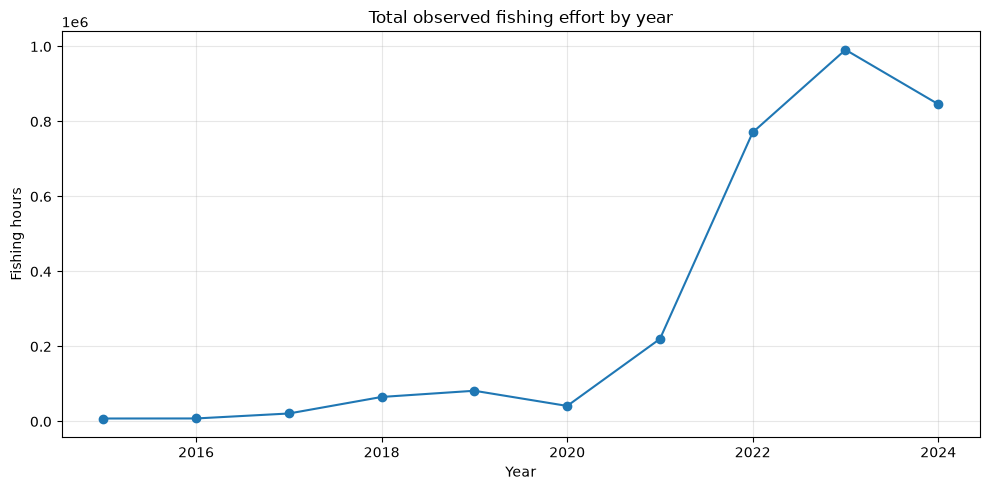

In [21]:
# NOTE: cells must be counted as distinct (lat, lon) pairs per year.
# Counting nunique() on cell_ll_lat alone would count distinct latitudes only
# and severely undercount the observed cells.
global_yearly = (
    trend_monthly
    .groupby("year", as_index=False)
    .agg(
        fishing_hours=("fishing_hours", "sum"),
        total_hours=("total_hours", "sum"),
    )
)
_cells_per_year = (
    trend_monthly
    .drop_duplicates(subset=["year", "cell_ll_lat", "cell_ll_lon"])
    .groupby("year")
    .size()
    .rename("cells_observed")
    .reset_index()
)
global_yearly = global_yearly.merge(_cells_per_year, on="year", how="left")

display(global_yearly)

plt.figure(figsize=(10, 5))
plt.plot(global_yearly["year"], global_yearly["fishing_hours"], marker="o")
plt.xlabel("Year")
plt.ylabel("Fishing hours")
plt.title("Total observed fishing effort by year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 6. Annual effort per cell

A raw annual total can be influenced by the number of months observed. We therefore also calculate **mean monthly fishing hours** within each cell-year as a sensitivity measure.


In [22]:
annual_cell_valid["mean_monthly_fishing_hours"] = (
    annual_cell_valid["fishing_hours"]
    / annual_cell_valid["months_available"]
)

display(
    annual_cell_valid[
        [
            "year", "cell_ll_lat", "cell_ll_lon",
            "fishing_hours", "months_available",
            "mean_monthly_fishing_hours"
        ]
    ].head()
)


,year,cell_ll_lat,cell_ll_lon,fishing_hours,months_available,mean_monthly_fishing_hours
206,2015,15.1000,72.0000,63.2860,4,15.8215
322,2015,17.6000,83.3000,25.5460,5,5.1092
327,2015,17.7000,83.3000,71.9604,7,10.2801
328,2015,17.7000,83.4000,175.2127,7,25.0304
329,2015,17.7000,83.5000,3.9172,3,1.3057


### 7. Cell-level trend estimation

For every spatial cell we fit, on **mean monthly fishing hours** (annual effort normalised by months observed, so years with different coverage are comparable):

`Mean monthly effort = β₀ + β₁ × Year + error`

- `β₁ < 0` → declining fishing effort
- `β₁ > 0` → increasing fishing effort
- `β₁ ≈ 0` → little linear change

We calculate both linear regression and Spearman rank correlation as complementary trend diagnostics. Raw annual `fishing_hours` is retained for context, but the regression uses the coverage-normalised measure.

A cell needs at least **5 annual observations** (`MIN_YEARS = 5`) to qualify. The previous combination (≥10 months per year plus ≥7 years) was infeasible: it left zero eligible cells because the sparsest-observed cells never reach 10 months in enough years.


In [23]:
MIN_YEARS = 5
TREND_VALUE_COL = "mean_monthly_fishing_hours"

def calculate_trend(group):
    g = group.sort_values("year")

    if g["year"].nunique() < MIN_YEARS:
        return pd.Series({
            "n_years": int(g["year"].nunique()),
            "slope_hours_per_year": np.nan,
            "intercept": np.nan,
            "r_squared": np.nan,
            "regression_p_value": np.nan,
            "spearman_rho": np.nan,
            "spearman_p_value": np.nan,
            "first_year": np.nan,
            "last_year": np.nan,
            "first_effort": np.nan,
            "last_effort": np.nan,
            "absolute_change_hours": np.nan,
            "percent_change": np.nan,
        })

    x = g["year"].to_numpy(dtype=float)
    y = g[TREND_VALUE_COL].to_numpy(dtype=float)

    # Constant series: linregress/spearmanr are undefined; report a zero slope.
    if np.all(~np.isnan(y)) and np.nanstd(y) == 0:
        return pd.Series({
            "n_years": int(len(g)),
            "slope_hours_per_year": 0.0,
            "intercept": float(np.nanmean(y)),
            "r_squared": 0.0,
            "regression_p_value": np.nan,
            "spearman_rho": np.nan,
            "spearman_p_value": np.nan,
            "first_year": int(g["year"].iloc[0]),
            "last_year": int(g["year"].iloc[-1]),
            "first_effort": float(y[0]),
            "last_effort": float(y[-1]),
            "absolute_change_hours": 0.0,
            "percent_change": 0.0,
        })

    lr = linregress(x, y)
    rho, rho_p = spearmanr(x, y)

    first_effort = y[0]
    last_effort = y[-1]
    pct_change = (
        (last_effort - first_effort) / first_effort * 100
        if first_effort != 0 else np.nan
    )

    return pd.Series({
        "n_years": int(len(g)),
        "slope_hours_per_year": lr.slope,
        "intercept": lr.intercept,
        "r_squared": lr.rvalue ** 2,
        "regression_p_value": lr.pvalue,
        "spearman_rho": rho,
        "spearman_p_value": rho_p,
        "first_year": int(g["year"].iloc[0]),
        "last_year": int(g["year"].iloc[-1]),
        "first_effort": first_effort,
        "last_effort": last_effort,
        "absolute_change_hours": last_effort - first_effort,
        "percent_change": pct_change,
    })

cell_trends = (
    annual_cell_valid
    .groupby(["cell_ll_lat", "cell_ll_lon"], group_keys=False)
    .apply(calculate_trend, include_groups=False)
    .reset_index()
)

print(f"Trend metric: {TREND_VALUE_COL}")
print("Trend cells:", len(cell_trends))
print("Eligible cells (n_years >= MIN_YEARS):", int((cell_trends["n_years"] >= MIN_YEARS).sum()))
display(cell_trends.head())


Trend metric: mean_monthly_fishing_hours
Trend cells: 8697
Eligible cells (n_years >= MIN_YEARS): 557


,cell_ll_lat,cell_ll_lon,n_years,slope_hours_per_year,intercept,r_squared,regression_p_value,spearman_rho,spearman_p_value,first_year,last_year,first_effort,last_effort,absolute_change_hours,percent_change
0,2.7000,69.0000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4.5000,69.0000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.5000,69.2000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5.8000,68.3000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5.8000,78.2000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 8. Classify regional trends

A cell is classified as:

- **Declining** — negative slope and regression `p < 0.05`
- **Increasing** — positive slope and regression `p < 0.05`
- **Stable / not significant** — slope not statistically significant
- **Insufficient data** — fewer than the minimum annual observations

The significance threshold is a screening rule, not proof of causation.


In [24]:
ALPHA = 0.05

conditions = [
    cell_trends["n_years"].lt(MIN_YEARS),
    cell_trends["regression_p_value"].lt(ALPHA)
    & cell_trends["slope_hours_per_year"].lt(0),
    cell_trends["regression_p_value"].lt(ALPHA)
    & cell_trends["slope_hours_per_year"].gt(0),
]
choices = [
    "Insufficient data",
    "Declining",
    "Increasing",
]
cell_trends["trend_class"] = np.select(
    conditions, choices, default="Stable / not significant",
)

trend_counts = (
    cell_trends["trend_class"]
    .value_counts()
    .rename_axis("trend_class")
    .reset_index(name="number_of_cells")
)

trend_counts["percentage"] = (
    trend_counts["number_of_cells"] / len(cell_trends) * 100
)

display(trend_counts)


,trend_class,number_of_cells,percentage
0,Insufficient data,8140,93.5955
1,Stable / not significant,511,5.8756
2,Increasing,39,0.4484
3,Declining,7,0.0805


### 9. Strongest declining regions

This ranks cells by estimated annual change in fishing hours. These are candidate regions for deeper investigation.


In [25]:
declining = (
    cell_trends[cell_trends["trend_class"] == "Declining"]
    .sort_values("slope_hours_per_year")
    .copy()
)

print(f"Declining cells: {len(declining)}")
if declining.empty:
    print("No statistically declining cells at alpha = 0.05.")
else:
    display(
        declining[
            [
                "cell_ll_lat", "cell_ll_lon", "n_years",
                "slope_hours_per_year", "r_squared",
                "regression_p_value", "spearman_rho",
                "spearman_p_value", "percent_change"
            ]
        ].head(20)
    )


Declining cells: 7


,cell_ll_lat,cell_ll_lon,n_years,slope_hours_per_year,r_squared,regression_p_value,spearman_rho,spearman_p_value,percent_change
7451,18.5000,72.0000,5.0000,-10.8746,0.8380,0.0291,-1.0000,0.0000,-98.0609
6652,17.0000,72.8000,8.0000,-8.7219,0.5152,0.0450,-0.8095,0.0149,-75.4889
7455,18.5000,72.4000,5.0000,-6.5667,0.9263,0.0087,-1.0000,0.0000,-89.5283
7500,18.6000,72.4000,6.0000,-5.2074,0.6758,0.0447,-0.8857,0.0188,-75.1696
7499,18.6000,72.3000,6.0000,-4.1398,0.9339,0.0017,-0.9429,0.0048,-69.4109
7345,18.2000,72.5000,6.0000,-4.0945,0.6716,0.0459,-0.7714,0.0724,-78.8163
6768,17.2000,72.5000,5.0000,-3.8394,0.8206,0.0342,-0.9000,0.0374,-92.6983


### 10. Strongest increasing regions


In [26]:
increasing = (
    cell_trends[cell_trends["trend_class"] == "Increasing"]
    .sort_values("slope_hours_per_year", ascending=False)
    .copy()
)

print(f"Increasing cells: {len(increasing)}")
if increasing.empty:
    print("No statistically increasing cells at alpha = 0.05.")
else:
    display(
        increasing[
            [
                "cell_ll_lat", "cell_ll_lon", "n_years",
                "slope_hours_per_year", "r_squared",
                "regression_p_value", "spearman_rho",
                "spearman_p_value", "percent_change"
            ]
        ].head(20)
    )


Increasing cells: 39


,cell_ll_lat,cell_ll_lon,n_years,slope_hours_per_year,r_squared,regression_p_value,spearman_rho,spearman_p_value,percent_change
4417,13.6000,73.6000,5.0000,63.5021,0.8170,0.0353,0.9000,0.0374,"1,614.1782"
4501,13.7000,73.6000,5.0000,49.2664,0.8074,0.0382,0.9000,0.0374,"1,237.0268"
4670,13.9000,73.5000,5.0000,48.7281,0.8308,0.0312,0.9000,0.0374,"1,768.2318"
4500,13.7000,73.5000,5.0000,43.5645,0.8033,0.0395,0.9000,0.0374,935.7865
4590,13.8000,73.6000,5.0000,42.8379,0.7911,0.0434,0.9000,0.0374,880.9708
4589,13.8000,73.5000,6.0000,40.0262,0.8405,0.0101,0.8286,0.0416,926.8776
4671,13.9000,73.6000,5.0000,39.6910,0.8855,0.0170,1.0000,0.0000,"2,078.0266"
4749,14.0000,73.6000,6.0000,34.2012,0.7969,0.0166,0.7714,0.0724,850.8568
5151,14.6000,73.4000,6.0000,33.3044,0.8274,0.0119,0.9429,0.0048,882.9701
4748,14.0000,73.5000,5.0000,28.0981,0.8661,0.0217,1.0000,0.0000,410.7946


### 11. Inspect the strongest declining cells

A significant linear trend can hide a late-period reversal. The following plots inspect the actual annual observations for the strongest declining cells.


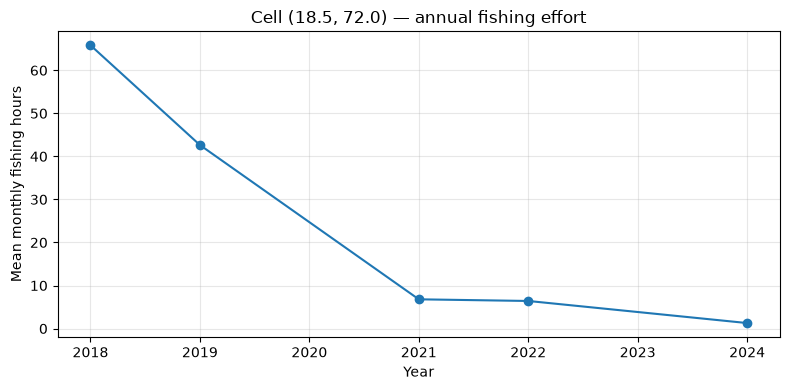

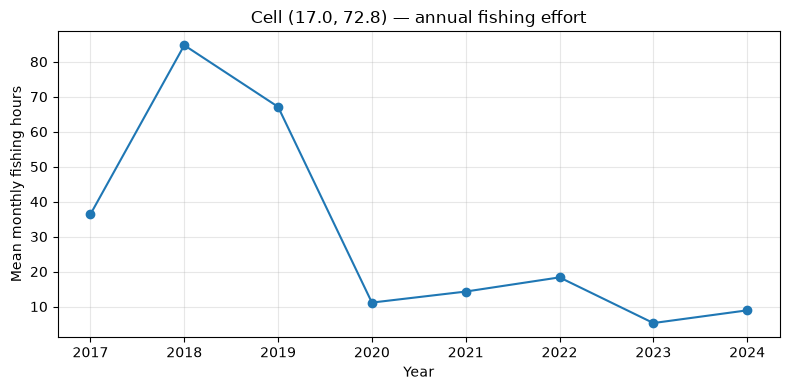

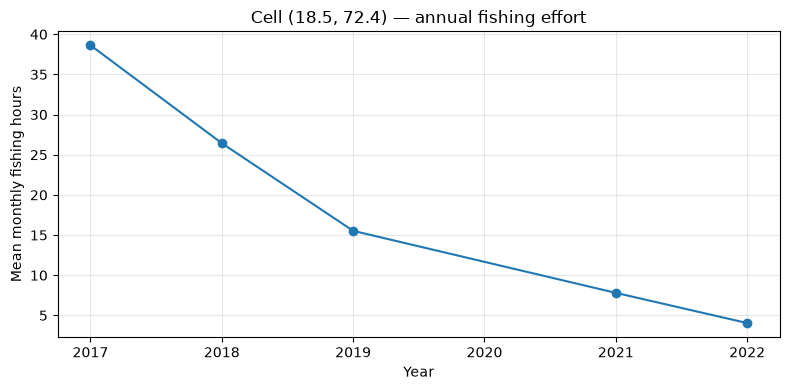

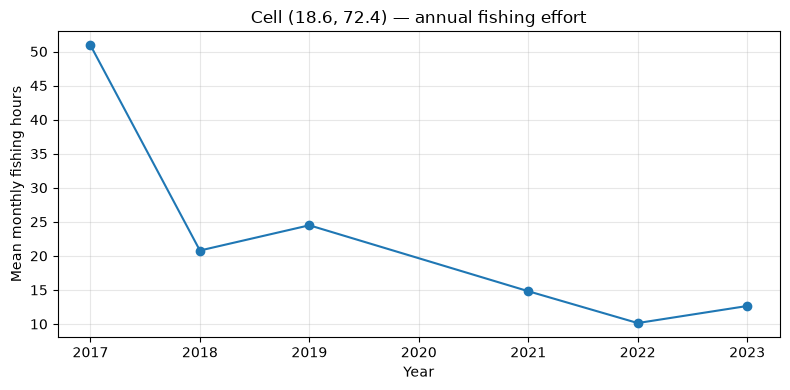

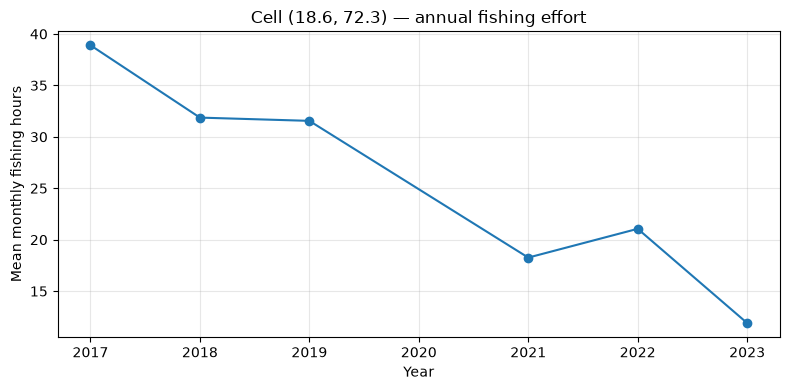

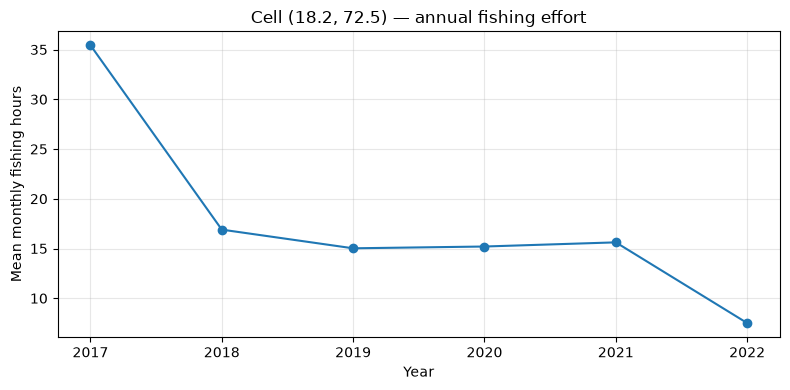

In [27]:
TOP_N = 6

if declining.empty:
    print("No declining cells to inspect.")
else:
    for lat, lon in declining.head(TOP_N)[
        ["cell_ll_lat", "cell_ll_lon"]
    ].itertuples(index=False, name=None):
        g = annual_cell_valid[
            (annual_cell_valid["cell_ll_lat"] == lat)
            & (annual_cell_valid["cell_ll_lon"] == lon)
        ].sort_values("year")

        plt.figure(figsize=(8, 4))
        plt.plot(g["year"], g["mean_monthly_fishing_hours"], marker="o")
        plt.xlabel("Year")
        plt.ylabel("Mean monthly fishing hours")
        plt.title(f"Cell ({lat:.1f}, {lon:.1f}) — annual fishing effort")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()


### 12. Compare effort with vessel activity

A reduction in fishing hours can happen because fewer vessels are active, vessels spend less time fishing, or activity shifts spatially.

At the cell-year level we therefore calculate fishing hours per active vessel as a supplementary diagnostic.


In [28]:
# vessel_months double-counts vessels seen in several months; prefer the true
# annual unique count when it could be recomputed (see Section 4).
_vessel_denom = annual_cell_valid["active_vessels_unique"]
if _vessel_denom.isna().all():
    print("True annual uniques unavailable; falling back to vessel_months "
          "(interpret as hours per vessel-month, not per unique vessel).")
    _vessel_denom = annual_cell_valid["vessel_months"]

annual_cell_valid["hours_per_active_vessel"] = np.where(
    _vessel_denom > 0,
    annual_cell_valid["fishing_hours"]
    / _vessel_denom,
    np.nan,
)

display(
    annual_cell_valid[
        [
            "year", "cell_ll_lat", "cell_ll_lon",
            "fishing_hours", "vessel_months", "active_vessels_unique",
            "hours_per_active_vessel"
        ]
    ].head()
)


,year,cell_ll_lat,cell_ll_lon,fishing_hours,vessel_months,active_vessels_unique,hours_per_active_vessel
206,2015,15.1000,72.0000,63.2860,4,1,63.2860
322,2015,17.6000,83.3000,25.5460,5,1,25.5460
327,2015,17.7000,83.3000,71.9604,7,1,71.9604
328,2015,17.7000,83.4000,175.2127,7,1,175.2127
329,2015,17.7000,83.5000,3.9172,3,1,3.9172


### 13. Spatial map of trend classes

The coordinates are the native GFW cell lower-left coordinates. No additional re-gridding is applied.


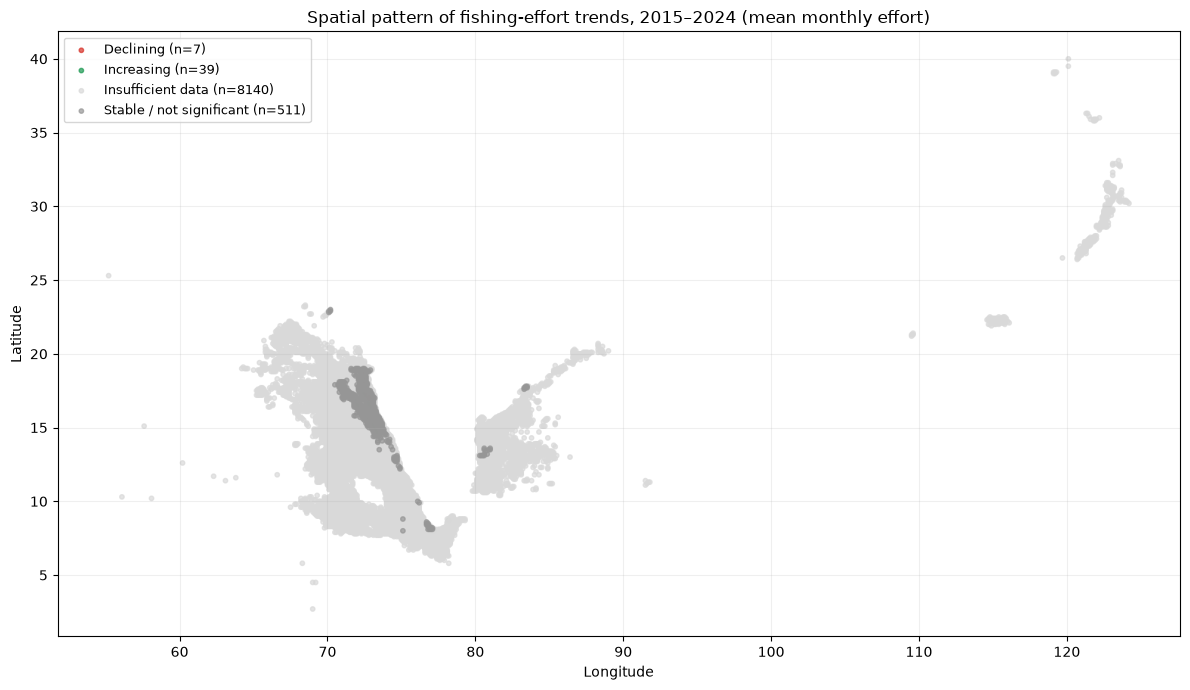

In [29]:
import matplotlib.patches as mpatches

plot_df = cell_trends.copy()

palette = {
    "Declining": "#d73027",
    "Increasing": "#1a9850",
    "Stable / not significant": "#969696",
    "Insufficient data": "#d9d9d9",
}
plot_df["color"] = plot_df["trend_class"].map(palette)

plt.figure(figsize=(12, 7))
for cls, grp in plot_df.groupby("trend_class"):
    plt.scatter(
        grp["cell_ll_lon"], grp["cell_ll_lat"],
        s=10, alpha=0.7, c=grp["color"], label=f"{cls} (n={len(grp)})",
    )
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial pattern of fishing-effort trends, 2015–2024 (mean monthly effort)")
plt.grid(alpha=0.2)
plt.legend(frameon=True, fontsize=9, loc="best")
plt.tight_layout()
plt.show()


### 14. Magnitude of negative trends


Declining cells to map: 7


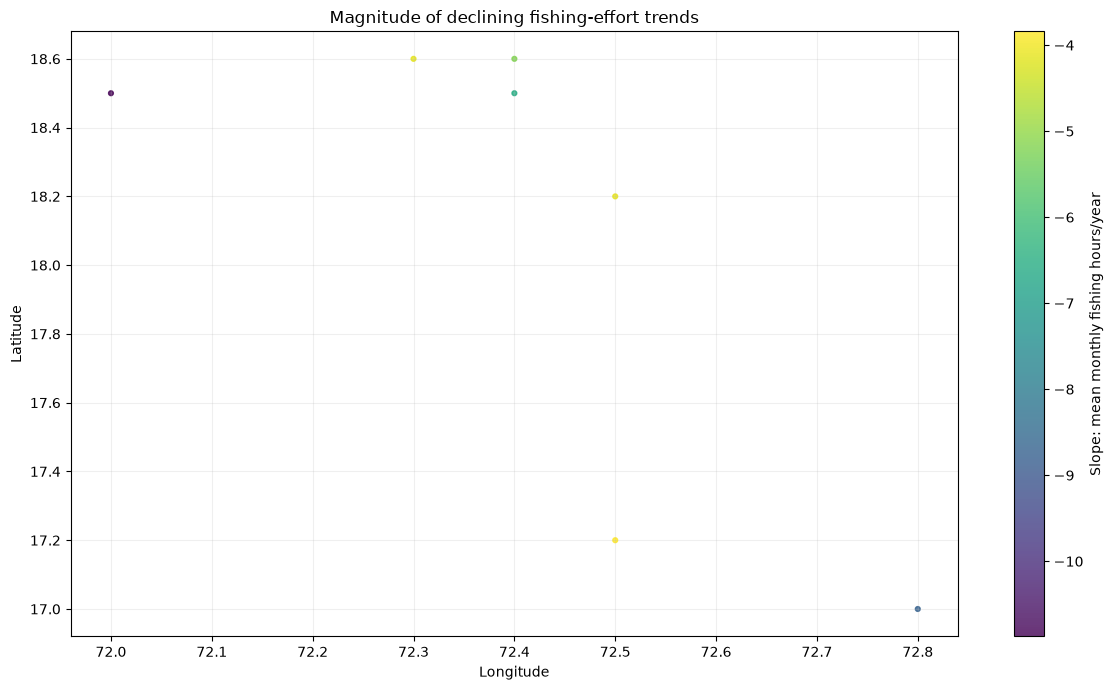

In [30]:
decline_map = cell_trends[
    cell_trends["trend_class"] == "Declining"
].copy()

print(f"Declining cells to map: {len(decline_map)}")
if decline_map.empty:
    print("No declining cells; skipping magnitude map.")
else:
    plt.figure(figsize=(12, 7))
    sc = plt.scatter(
        decline_map["cell_ll_lon"],
        decline_map["cell_ll_lat"],
        c=decline_map["slope_hours_per_year"],
        s=12,
        alpha=0.8,
    )
    plt.colorbar(sc, label="Slope: mean monthly fishing hours/year")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("Magnitude of declining fishing-effort trends")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


### 15. Export results

The trend table is the main output of this notebook and will be reused in the next stage.


In [31]:
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

cell_trends.to_parquet(TREND_PATH, index=False)

annual_cell_valid.to_parquet(
    ANALYSIS_DIR / "annual_cell_effort_2015_2024.parquet",
    index=False,
)

trend_counts.to_csv(
    ANALYSIS_DIR / "trend_class_summary.csv",
    index=False,
)

print("Saved:")
print(TREND_PATH)
print(ANALYSIS_DIR / "annual_cell_effort_2015_2024.parquet")
print(ANALYSIS_DIR / "trend_class_summary.csv")


Saved:
..\outputs\analysis\cell_effort_trends.parquet
..\outputs\analysis\annual_cell_effort_2015_2024.parquet
..\outputs\analysis\trend_class_summary.csv


### 16. Conclusions to record after execution

After running the notebook, answer:

1. Does total observed fishing effort increase or decrease over 2015–2024?
2. What fraction of analyzed cells are statistically declining?
3. Where are the strongest declining cells?
4. Are declines concentrated in particular regions?
5. Do declining cells also show fewer active vessels?
6. Does the pattern remain when using mean monthly effort?
7. Are there enough persistent declining regions to justify clustering?

**Important:** a decline in `fishing_hours` is a decline in observed fishing effort, not proof of declining fish productivity. Biological productivity requires catch, landings, biomass, or a comparable biological measure.

If the decline pattern is robust, the next stage is to characterize regional temporal trajectories with clustering and then investigate possible environmental, economic, regulatory, or fleet-related explanations.
